# Panel composition — new panel (production, 231 founders)

Descriptive distributions of the current production panel: variant classes
(SNP / indel / SV), SV size spectrum, allele-frequency spectrum, missingness,
per-founder carrier counts (cactus long-read vs PanGenie short-read cohorts),
and genomic density. All numbers computed directly from
`panel/arch3/chr{1..5}/var_pa_231_arch3_chr{1..5}.{var_pa,var_called,meta}.npz`
and should reconcile with `analysis/panel_qc/panel_stats/PANEL_STATS.md`
(`scripts/panel_stats_for_paper.py`) -- that report has the authoritative tables;
this notebook is the plotted companion.

**Supersedes** `preprocess_qc/notebooks/production_vcf_stats.ipynb`, which
answered this on the previous `founders_231_chr.vcf.gz` panel and is now
archived (`archive/preprocess_qc/`).

SV cutoff: length change `|alt_len - ref_len| > 50bp` (matches PANEL_STATS and
`build_sv_snp_ld.py`).


In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJ = "/global/scratch/users/tbellg/kmate"
CHROMS = [1, 2, 3, 4, 5]
NF = 231

PLOTDIR = f"{PROJ}/analysis/grenenet_selection/notebooks/plots"
os.makedirs(PLOTDIR, exist_ok=True)

# --- style: seaborn theme. Project convention: no chart titles / subplot titles
# anywhere -- markdown section headers + axis labels carry context instead. ---
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110})

CLASS_ORDER = ["SNP", "indel", "SV"]
KIND_ORDER = ["INS", "DEL", "MNP"]
# One coherent palette for the whole notebook: every semantic entity (class,
# cohort, indel/SV direction) gets its own fixed, non-overlapping color, used
# identically in every chart it appears in.
_pal = sns.color_palette("deep", 10)
CLASS_COLOR = {"SNP": _pal[0], "indel": _pal[2], "SV": _pal[3]}         # blue, green, red
# Cohort naming: "long-read" (cactus assemblies) vs "short-read" (PanGenie-genotyped)
# -- names the sequencing/assembly method, which is what actually drives the
# differences seen below, rather than the tool names.
COL_LONGREAD, COL_SHORTREAD = _pal[1], _pal[4]                          # orange, purple
KIND_COLOR = {"INS": _pal[9], "DEL": _pal[5], "MNP": _pal[6]}           # cyan, brown, pink

longread_set = set(l.strip() for l in
    open(f"{PROJ}/panel/pangenie_genotyping/data/cactus_80_ecotypes.txt"))

# ---- UNIT DEFINITION (project rule: SVs are analysed as EVENTS, not alleles) ----
# SNPs and short indels (<= 50 bp): one unit per panel record. SVs (> 50 bp): one unit per Truvari EVENT
# (`arch3_event_map.npz`, collapse defaults 0.95 / 0.95 / 500 bp, within a pangenome bubble and type). A founder
# CARRIES an event if it carries any member allele and is CALLED if called at any member (union rule of
# r1_sv_negative_selection/_build_event_units.py). Event position / size / direction = its most-carried member.
import scipy.sparse as sp
EVENT_DIR = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection/r1_sv_negative_selection/results/sv_adaptive"
BM = np.load(f"{EVENT_DIR}/arch3_bubble_map.npz"); EM = np.load(f"{EVENT_DIR}/arch3_event_map.npz")

def restrict(z, cols, N):
    # CSR (founders x records) npz -> founders x len(cols) CSR keeping only `cols` (all values 1)
    remap = np.full(N, -1, np.int64); remap[cols] = np.arange(cols.size)
    ip, ix = z["indptr"], z["indices"]
    rows = np.repeat(np.arange(NF), np.diff(ip))
    keep = remap[ix] >= 0
    return sp.csr_matrix((np.ones(int(keep.sum()), np.int8), (rows[keep], remap[ix[keep]])), shape=(NF, cols.size))

rec_chrom, rec_pos, rec_cls, rec_kind, rec_svsize, rec_ac, rec_an = [], [], [], [], [], [], []
rec_miss_lr, rec_miss_sr = [], []           # per-UNIT missing count, long-read / short-read side
n_alt_tot = np.zeros(NF, dtype=np.int64)         # per-founder ALT-carrier UNIT count (all classes)
n_called_tot = np.zeros(NF, dtype=np.int64)      # per-founder called UNIT count
n_snp_alt_tot = np.zeros(NF, dtype=np.int64)     # per-founder SNP-only ALT-carrier count
n_indel_alt_tot = np.zeros(NF, dtype=np.int64)   # per-founder indel-only ALT-carrier count
n_sv_alt_tot = np.zeros(NF, dtype=np.int64)      # per-founder SV-EVENT carrier count
n_alt_mac2 = np.zeros(NF, dtype=np.int64)        # same 4, restricted to MAC>=2 units
n_snp_alt_mac2 = np.zeros(NF, dtype=np.int64)
n_indel_alt_mac2 = np.zeros(NF, dtype=np.int64)
n_sv_alt_mac2 = np.zeros(NF, dtype=np.int64)
founders = None
is_longread = None      # bool array, founder order, set once founders is known
N_LR = N_SR = None
N_total = 0             # number of UNITS (SNP + indel records + SV events)
N_sv_records = 0        # for reference: SV records collapsed into the events

for c in CHROMS:
    cl, Cl = f"chr{c}", f"Chr{c}"
    m = np.load(f"{PROJ}/panel/arch3/{cl}/var_pa_231_arch3_{cl}.meta.npz", allow_pickle=True)
    pos = m["pos"]; rl = m["ref_len"].astype(np.int64); al = m["alt_len"].astype(np.int64)
    if founders is None:
        founders = [str(x) for x in m["founders"]]
        is_longread = np.array([f in longread_set for f in founders])
        N_LR, N_SR = int(is_longread.sum()), int((~is_longread).sum())
    N = len(pos)
    ldiff = np.abs(al - rl)
    snp = (rl == 1) & (al == 1)
    sv  = ldiff > 50
    indel = (~snp) & (~sv)
    cls = np.where(snp, "SNP", np.where(sv, "SV", "indel"))
    ins  = al > rl
    dele = rl > al
    mnp  = (rl == al) & (rl > 1)
    kind = np.where(snp, "SNP", np.where(ins, "INS", np.where(dele, "DEL", "MNP")))
    keepr = ~sv                                  # SNP / indel records stay one unit per record

    zp = np.load(f"{PROJ}/panel/arch3/{cl}/var_pa_231_arch3_{cl}.var_pa.npz", allow_pickle=False)
    zc = np.load(f"{PROJ}/panel/arch3/{cl}/var_pa_231_arch3_{cl}.var_called.npz", allow_pickle=False)
    ac = np.bincount(zp["indices"], minlength=N).astype(np.int32)
    an = np.bincount(zc["indices"], minlength=N).astype(np.int32)
    mac_keep = np.minimum(ac, an - ac) >= 2   # per-record MAC>=2 mask (SNP / indel records)

    # ---- SV events: union over member alleles
    cols = BM[f"{Cl}_rec"]; evid = EM[f"{Cl}_bubble"]
    assert np.array_equal(np.sort(cols), np.where(sv)[0]), "bubble-map records must be the >50bp records"
    n_ev = int(evid.max()) + 1
    Mm = sp.csr_matrix((np.ones(evid.size, np.int8), (np.arange(evid.size), evid)), shape=(evid.size, n_ev))
    EvP = ((restrict(zp, cols, N) @ Mm) > 0).tocsr()          # founders x events: carries any member
    EvC = ((restrict(zc, cols, N) @ Mm) > 0).tocsr()          # founders x events: called at any member
    ev_ac = np.asarray(EvP.sum(0)).ravel(); ev_an = np.asarray(EvC.sum(0)).ravel()
    ev_mac2 = np.minimum(ev_ac, ev_an - ev_ac) >= 2
    order = np.lexsort((np.arange(cols.size), -ac[cols], evid))   # per event: most-carried member first
    first = order[np.r_[True, np.diff(evid[order]) != 0]]
    assert first.size == n_ev
    rep = cols[first]
    ev_pos = pos[rep]; ev_size = ldiff[rep]; ev_kind = np.where(al[rep] > rl[rep], "INS", "DEL")
    ev_row_alt = np.asarray(EvP.sum(1)).ravel(); ev_row_called = np.asarray(EvC.sum(1)).ravel()
    ev_row_alt_mac2 = np.asarray(EvP[:, np.where(ev_mac2)[0]].sum(1)).ravel()

    # ---- per-founder tallies (non-SV records + events)
    ip_p = zp["indptr"]; row_nnz_p = ip_p[1:] - ip_p[:-1]
    ip_c = zc["indptr"]; row_nnz_c = ip_c[1:] - ip_c[:-1]
    row = np.repeat(np.arange(NF), row_nnz_p)
    idx = zp["indices"]
    snp_col, indel_col, nonsv_col = snp[idx], indel[idx], keepr[idx]
    mac2_col = mac_keep[idx]
    n_alt_tot        += np.bincount(row[nonsv_col], minlength=NF) + ev_row_alt
    n_snp_alt_tot    += np.bincount(row[snp_col], minlength=NF)
    n_indel_alt_tot  += np.bincount(row[indel_col], minlength=NF)
    n_sv_alt_tot     += ev_row_alt
    n_alt_mac2       += np.bincount(row[mac2_col & nonsv_col], minlength=NF) + ev_row_alt_mac2
    n_snp_alt_mac2   += np.bincount(row[snp_col & mac2_col], minlength=NF)
    n_indel_alt_mac2 += np.bincount(row[indel_col & mac2_col], minlength=NF)
    n_sv_alt_mac2    += ev_row_alt_mac2

    row_c = np.repeat(np.arange(NF), row_nnz_c)
    idx_c = zc["indices"]
    n_called_tot += np.bincount(row_c[keepr[idx_c]], minlength=NF) + ev_row_called
    # per-unit called count, split by cohort -- which side (long-read vs short-read) drives missingness
    lr_row_c = is_longread[row_c]
    n_called_lr = np.bincount(idx_c[lr_row_c], minlength=N)[keepr]
    n_called_sr = np.bincount(idx_c[~lr_row_c], minlength=N)[keepr]
    ev_called_lr = np.asarray(EvC[np.where(is_longread)[0], :].sum(0)).ravel()
    ev_called_sr = np.asarray(EvC[np.where(~is_longread)[0], :].sum(0)).ravel()
    rec_miss_lr.append(np.concatenate([N_LR - n_called_lr, N_LR - ev_called_lr]))
    rec_miss_sr.append(np.concatenate([N_SR - n_called_sr, N_SR - ev_called_sr]))

    nU = int(keepr.sum()) + n_ev
    rec_chrom.append(np.full(nU, Cl))
    rec_pos.append(np.concatenate([pos[keepr], ev_pos]))
    rec_cls.append(np.concatenate([cls[keepr], np.full(n_ev, "SV")]))
    rec_kind.append(np.concatenate([kind[keepr], ev_kind]))
    rec_svsize.append(np.concatenate([np.zeros(int(keepr.sum()), np.int64), ev_size]))
    rec_ac.append(np.concatenate([ac[keepr], ev_ac])); rec_an.append(np.concatenate([an[keepr], ev_an]))
    N_total += nU; N_sv_records += cols.size
    print(f"  {Cl}: {int(keepr.sum()):,} SNP/indel records + {n_ev:,} SV events (from {cols.size:,} SV records)")

rec = pd.DataFrame({
    "chrom": np.concatenate(rec_chrom), "pos": np.concatenate(rec_pos),
    "cls": np.concatenate(rec_cls), "kind": np.concatenate(rec_kind),
    "sv_size": np.concatenate(rec_svsize),
    "ac": np.concatenate(rec_ac), "an": np.concatenate(rec_an),
    "n_miss_lr": np.concatenate(rec_miss_lr), "n_miss_sr": np.concatenate(rec_miss_sr),
})
rec["maf"] = np.where(rec.an > 0, np.minimum(rec.ac, rec.an - rec.ac) / rec.an.replace(0, 1), np.nan)

cohort = np.array(["long-read" if lr else "short-read" for lr in is_longread])
founder = pd.DataFrame({
    "founder": founders, "cohort": cohort,
    "n_alt": n_alt_tot, "n_called": n_called_tot, "n_missing": N_total - n_called_tot,
    "n_snp_alt": n_snp_alt_tot, "n_indel_alt": n_indel_alt_tot, "n_sv_alt": n_sv_alt_tot,
    "n_alt_mac2": n_alt_mac2, "n_snp_alt_mac2": n_snp_alt_mac2,
    "n_indel_alt_mac2": n_indel_alt_mac2, "n_sv_alt_mac2": n_sv_alt_mac2,
})

print(f"\n{N_total:,} units genome-wide ({N_sv_records:,} SV records collapsed into events), {len(founder):,} founders "
      f"({N_LR} long-read + {N_SR} short-read)")
print(rec.cls.value_counts().rename("n"))

  Chr1: 2,095,295 SNP/indel records + 23,586 SV events (from 59,128 SV records)


  Chr2: 1,423,871 SNP/indel records + 15,435 SV events (from 39,514 SV records)


  Chr3: 1,553,581 SNP/indel records + 16,427 SV events (from 39,096 SV records)


  Chr4: 1,331,821 SNP/indel records + 14,654 SV events (from 36,299 SV records)


  Chr5: 1,858,610 SNP/indel records + 19,838 SV events (from 52,431 SV records)



8,353,118 units genome-wide (226,468 SV records collapsed into events), 231 founders (80 long-read + 151 short-read)
cls
SNP      6237063
indel    2026115
SV         89940
Name: n, dtype: int64


## 1. Variant class composition

genome-wide: {'SNP': 6237063, 'indel': 2026115, 'SV': 89940}
(cross-check vs PANEL_STATS.md §2 records: SNP 6,237,063 / indel 2,026,115 -- unchanged; SV: 226,468 records -> 89,940 events, 226,468 / 89,940 expected)


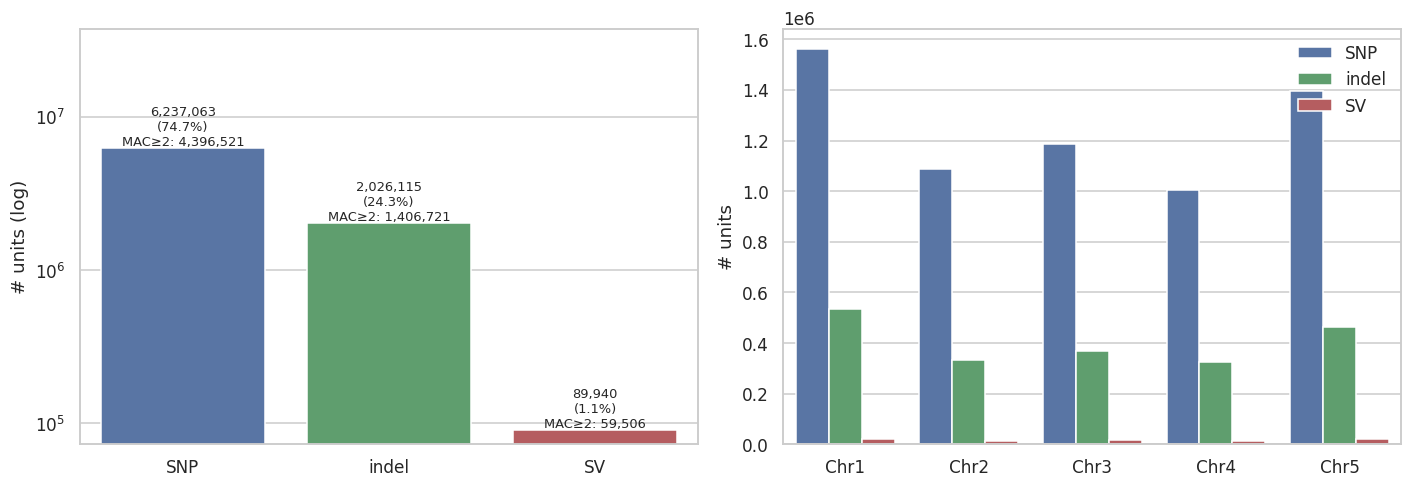

In [2]:
# 1. Variant class composition (SNP / indel / SV), genome-wide + per chromosome
counts = rec.cls.value_counts().reindex(CLASS_ORDER)
print("genome-wide:", dict(counts))
print("(cross-check vs PANEL_STATS.md §2 records: SNP 6,237,063 / indel 2,026,115 -- unchanged; "
      f"SV: {N_sv_records:,} records -> {int(counts['SV']):,} events, 226,468 / 89,940 expected)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
comp_df = counts.rename_axis("cls").reset_index(name="n")
sns.barplot(data=comp_df, x="cls", y="n", hue="cls", order=CLASS_ORDER,
            palette=CLASS_COLOR, legend=False, ax=ax)
ax.set_yscale("log"); ax.set_ylabel("# units (log)"); ax.set_xlabel("")
ax.set_ylim(top=counts.values.max() * 6)   # headroom so the top label clears the frame
mac2_counts = {c: int((np.minimum(rec.loc[rec.cls == c, "ac"], rec.loc[rec.cls == c, "an"] - rec.loc[rec.cls == c, "ac"]) >= 2).sum())
               for c in CLASS_ORDER}
for i, cl_ in enumerate(CLASS_ORDER):
    n = counts[cl_]
    ax.annotate(f"{n:,}\n({100*n/N_total:.1f}%)\nMAC≥2: {mac2_counts[cl_]:,}",
                (i, n), ha="center", va="bottom", fontsize=8.5)

ax = axes[1]
pc = rec.groupby(["chrom", "cls"]).size().rename("n").reset_index()
pc["chrom"] = pd.Categorical(pc["chrom"], [f"Chr{c}" for c in CHROMS], ordered=True)
sns.barplot(data=pc, x="chrom", y="n", hue="cls", hue_order=CLASS_ORDER, palette=CLASS_COLOR, ax=ax)
ax.set_ylabel("# units"); ax.set_xlabel("")
ax.legend(frameon=False, title=None, loc="upper right")

plt.tight_layout()
fig.savefig(f"{PLOTDIR}/01_variant_class_composition.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Insertion vs deletion (indels + SVs)

cls    kind
indel  INS     715094
       DEL     899326
       MNP     411695
SV     INS      50231
       DEL      39709
       MNP          0
Name: n, dtype: int64
(indel INS/DEL/MNP are records; SV INS/DEL are events -- PANEL_STATS.md's record-level SV INS/DEL 172,220 / 54,248 no longer apply)


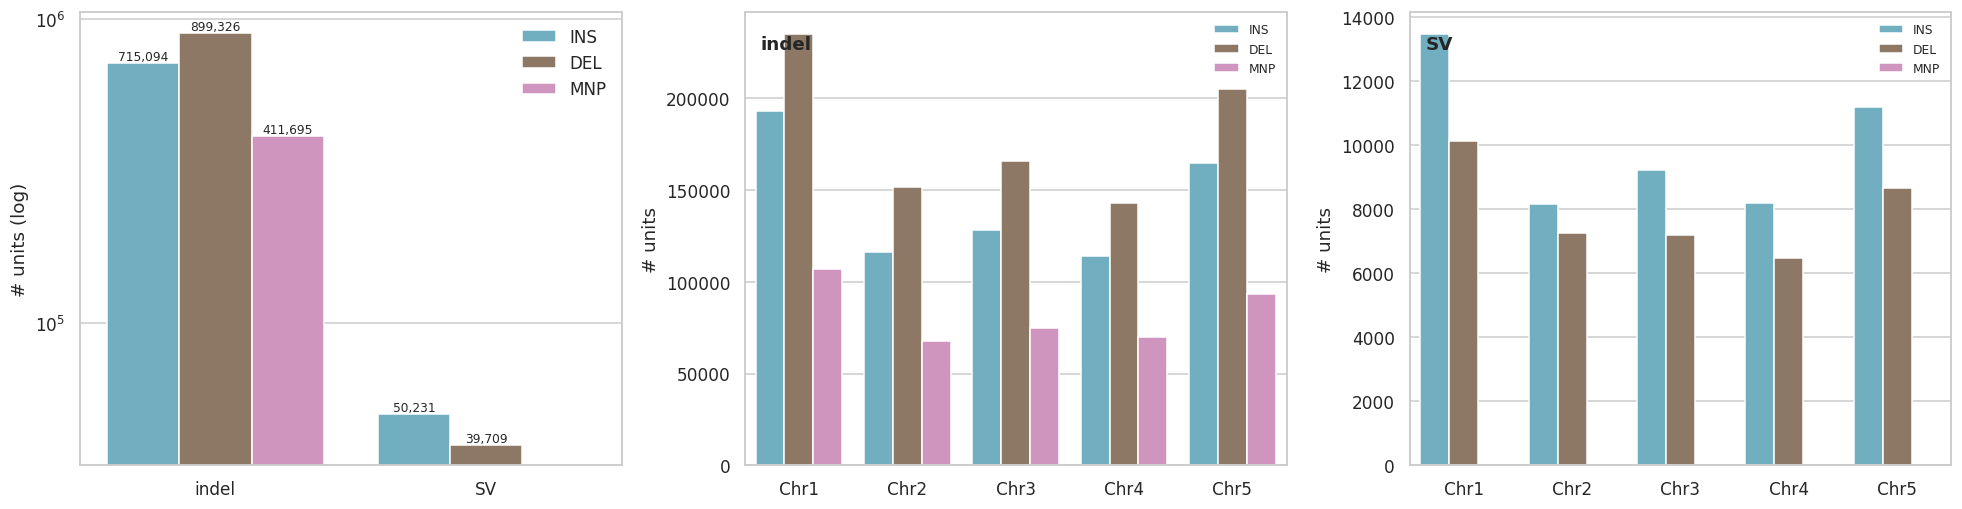

In [3]:
# 2. Insertion vs deletion, indels and SVs (SNPs have no direction, excluded).
# Same style as §1: genome-wide summary + per-chromosome breakdown.
kind_counts = rec[rec.cls.isin(["indel", "SV"])].groupby(["cls", "kind"]).size()
kind_counts = kind_counts.reindex(
    pd.MultiIndex.from_product([["indel", "SV"], KIND_ORDER], names=["cls", "kind"]), fill_value=0)
print(kind_counts.rename("n"))
print("(indel INS/DEL/MNP are records; SV INS/DEL are events -- PANEL_STATS.md's record-level SV INS/DEL "
      "172,220 / 54,248 no longer apply)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

ax = axes[0]
kd_df = kind_counts.rename("n").reset_index()
sns.barplot(data=kd_df, x="cls", y="n", hue="kind", order=["indel", "SV"],
            hue_order=KIND_ORDER, palette=KIND_COLOR, ax=ax)
ax.set_yscale("log"); ax.set_xlabel(""); ax.set_ylabel("# units (log)")
ax.legend(frameon=False, title=None)
for container, k in zip(ax.containers, KIND_ORDER):
    for bar, cl_ in zip(container, ["indel", "SV"]):
        n = int(kind_counts[(cl_, k)])
        ax.annotate(f"{n:,}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha="center", va="bottom", fontsize=8)

for ax, cl_ in zip(axes[1:], ["indel", "SV"]):
    pc = rec[rec.cls == cl_].groupby(["chrom", "kind"]).size().rename("n").reset_index()
    pc["chrom"] = pd.Categorical(pc["chrom"], [f"Chr{c}" for c in CHROMS], ordered=True)
    sns.barplot(data=pc, x="chrom", y="n", hue="kind", hue_order=KIND_ORDER, palette=KIND_COLOR, ax=ax)
    ax.set_ylabel("# units"); ax.set_xlabel("")
    ax.annotate(cl_, xy=(0.03, 0.95), xycoords="axes fraction", ha="left", va="top", fontweight="bold")
    ax.legend(frameon=False, title=None, fontsize=8)
plt.tight_layout()
fig.savefig(f"{PLOTDIR}/02_insertion_deletion.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. SV size spectrum

sv_size
50-100bp     21017
100bp-1kb    41775
1kb-10kb     23976
>10kb         3172
Name: n, dtype: int64
largest SV: 291,065 bp


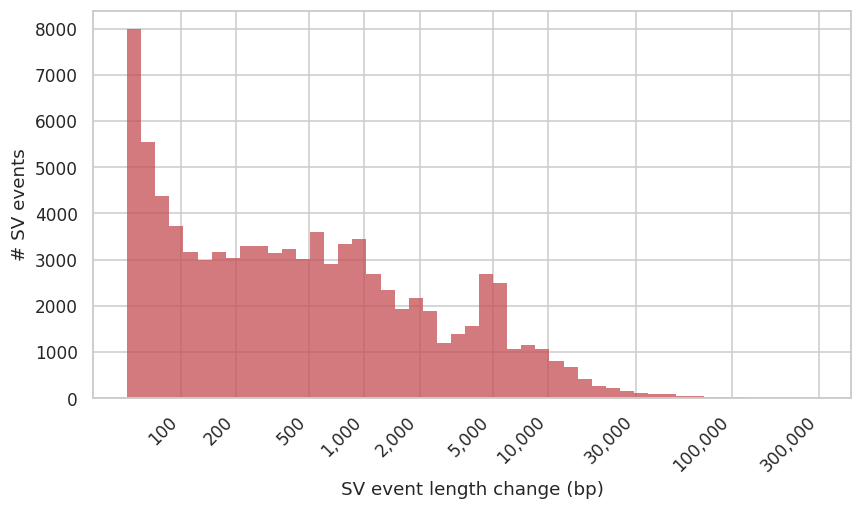

In [4]:
# 3. SV size spectrum (length change, bp) -- continuous distribution only;
# the binned bar version was redundant with this.
sv = rec[rec.cls == "SV"]
bin_edges = [50, 100, 1000, 10000, sv.sv_size.max() + 1]
bin_labels = ["50-100bp", "100bp-1kb", "1kb-10kb", ">10kb"]
sv_binned = pd.cut(sv.sv_size, bins=bin_edges, labels=bin_labels, right=True, include_lowest=True)
sv_counts = sv_binned.value_counts().reindex(bin_labels)
print(sv_counts.rename("n"))
print(f"largest SV: {int(sv.sv_size.max()):,} bp")

fig, ax = plt.subplots(figsize=(8, 4.8))
log_bins = np.logspace(np.log10(sv.sv_size.min()), np.log10(sv.sv_size.max()), 50)
sns.histplot(sv.sv_size, bins=log_bins, color=CLASS_COLOR["SV"], ax=ax)
ax.set_xscale("log")
ticks = [t for t in [50, 100, 200, 500, 1000, 2000, 5000, 10000, 30000, 100000, 300000]
         if sv.sv_size.min() <= t <= sv.sv_size.max() * 1.1]
ax.set_xticks(ticks); ax.set_xticklabels([f"{t:,}" for t in ticks], rotation=45, ha="right")
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("SV event length change (bp)"); ax.set_ylabel("# SV events")
plt.tight_layout()
fig.savefig(f"{PLOTDIR}/03_sv_size_spectrum.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Allele-frequency / MAC spectrum

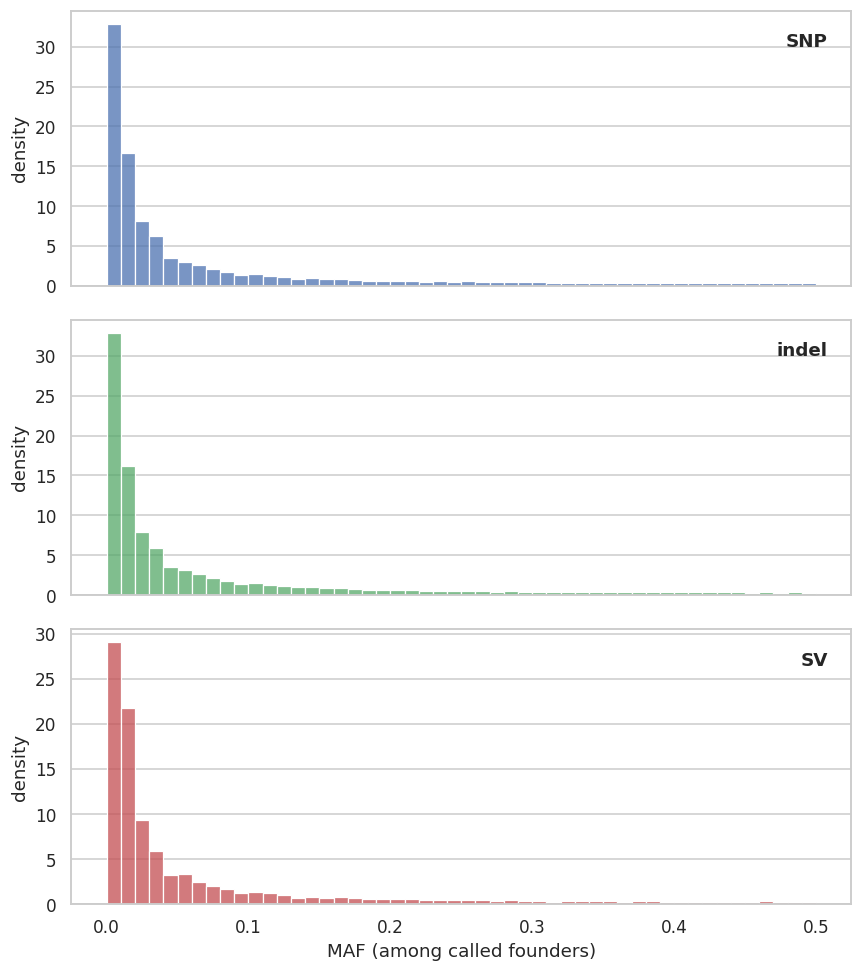

singletons (MAC=1) -- dropped by even the lightest MAC>=2 filter:


  SNP: 1,840,542 / 6,237,063 (29.5%)


  indel: 619,394 / 2,026,115 (30.6%)
  SV: 30,421 / 89,940 (33.8%)


MAC>=    2     5     10    20
class                        
SNP    70.5  46.1  32.3  21.1
indel  69.4  46.7  33.1  21.6
SV     66.2  40.5  26.9  16.7


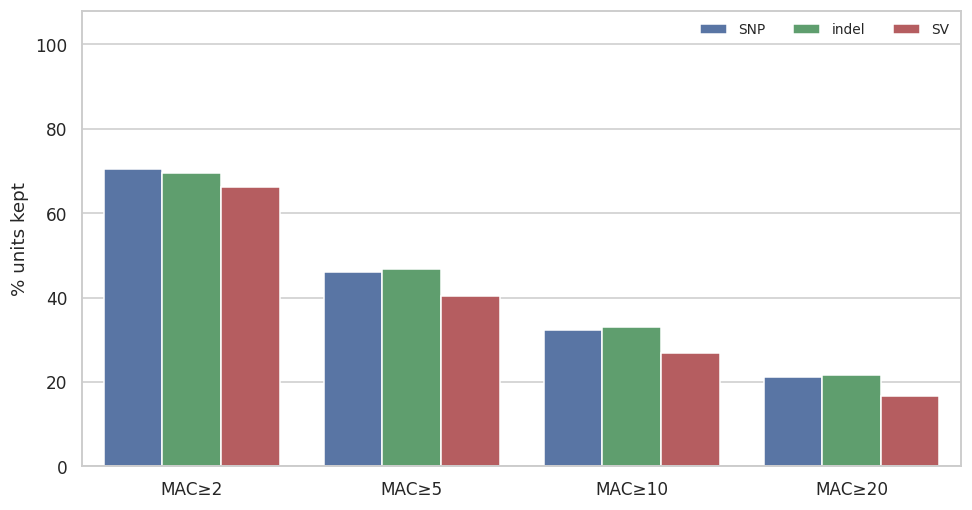

In [5]:
# 4. Allele-frequency / MAC spectrum, by class
# Small multiples stacked vertically (one row per class, shared x-axis) --
# overlaid on one axes was too hard to read given how differently-shaped
# the classes are.
fig, axes = plt.subplots(3, 1, figsize=(8, 9), sharex=True)
bins = np.linspace(0, 0.5, 51)
for ax, c in zip(axes, CLASS_ORDER):
    sns.histplot(rec.loc[rec.cls == c, "maf"].dropna(), bins=bins, color=CLASS_COLOR[c],
                 stat="density", ax=ax)
    ax.set_ylabel("density")
    ax.annotate(c, xy=(0.97, 0.92), xycoords="axes fraction", ha="right", va="top", fontweight="bold")
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("MAF (among called founders)")
plt.tight_layout()
fig.savefig(f"{PLOTDIR}/04a_maf_spectrum.png", dpi=150, bbox_inches="tight")
plt.show()

# MAC survival: the panel is segregating-only by construction (0<AC<AN for every
# record), so MAC>=1 is trivially 100% for every class and shows nothing -- start
# at MAC>=2 instead. Singleton (MAC=1) share is the informative "floor" number.
print("singletons (MAC=1) -- dropped by even the lightest MAC>=2 filter:")
for c in CLASS_ORDER:
    sub = rec[rec.cls == c]
    mac = np.minimum(sub.ac, sub.an - sub.ac)
    n_single = int((mac == 1).sum())
    print(f"  {c}: {n_single:,} / {len(sub):,} ({100*n_single/len(sub):.1f}%)")

thresholds_mac = [2, 5, 10, 20]
rows = []
for c in CLASS_ORDER:
    sub = rec[rec.cls == c]
    mac = np.minimum(sub.ac, sub.an - sub.ac)
    for t in thresholds_mac:
        rows.append({"class": c, "MAC>=": t, "pct": 100*(mac >= t).mean()})
mac_df = pd.DataFrame(rows)
print(mac_df.pivot(index="class", columns="MAC>=", values="pct").reindex(CLASS_ORDER).round(1))

# Grouped by MAC threshold (the 3 main x-categories), SNP/indel/SV side by side within each.
fig, ax = plt.subplots(figsize=(9, 4.8))
mac_df["MAC_label"] = mac_df["MAC>="].map(lambda t: f"MAC≥{t}")
mac_order = [f"MAC≥{t}" for t in thresholds_mac]
sns.barplot(data=mac_df, x="MAC_label", y="pct", hue="class", order=mac_order,
            hue_order=CLASS_ORDER, palette=CLASS_COLOR, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("% units kept"); ax.set_ylim(0, 108)
ax.legend(frameon=False, title=None, loc="upper right", ncol=3, fontsize=9)
plt.tight_layout()
fig.savefig(f"{PLOTDIR}/04b_mac_survival.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Missingness

Overall genotype missing rate: 14.30%


       mean  median
cls                
SNP    32.1    10.0
indel  34.8    20.0
SV     58.0    40.0



spike (140-160 missing, n=725,071 units): median short-read-missing 151/151, median long-read-missing 2/80


rest of units (n=7,628,047): median short-read-missing 5/151, median long-read-missing 0/80


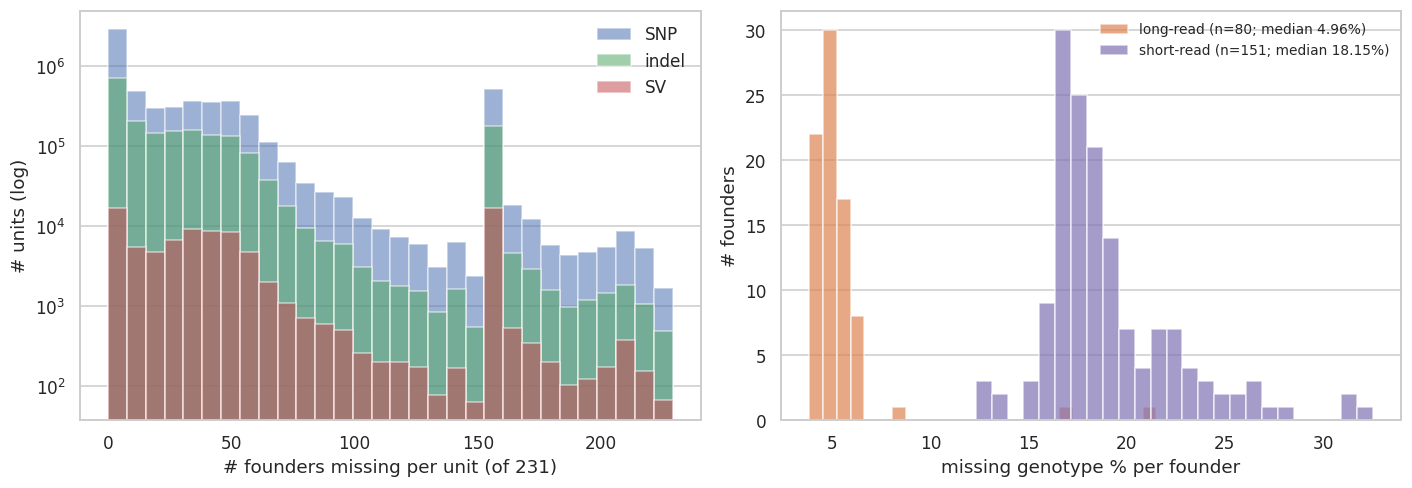

In [6]:
# 5. Missingness -- unit-level (by class; SV unit = event) and founder-level (by cohort)
rec["n_miss_founders"] = NF - rec.an   # raw count (of 231) rather than % -- more concrete; SV = event
rec["miss_frac"] = rec.n_miss_founders / NF
print("Overall genotype missing rate:",
      f"{100*(1 - rec.an.sum()/(NF*N_total)):.2f}%")
print(rec.groupby("cls").n_miss_founders.agg(["mean", "median"]).reindex(CLASS_ORDER).round(1))

# Check the ~150-missing spike: is it records where the long-read (cactus) side
# is called but the short-read (PanGenie, n=151) side is essentially all missing?
spike = rec[(rec.n_miss_founders >= 140) & (rec.n_miss_founders <= 160)]
other = rec[(rec.n_miss_founders < 140) | (rec.n_miss_founders > 160)]
print(f"\nspike (140-160 missing, n={len(spike):,} units): median short-read-missing "
      f"{int(spike.n_miss_sr.median())}/{N_SR}, median long-read-missing {int(spike.n_miss_lr.median())}/{N_LR}")
print(f"rest of units (n={len(other):,}): median short-read-missing "
      f"{int(other.n_miss_sr.median())}/{N_SR}, median long-read-missing {int(other.n_miss_lr.median())}/{N_LR}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
for c in CLASS_ORDER:
    ax.hist(rec.loc[rec.cls == c, "n_miss_founders"], bins=30, color=CLASS_COLOR[c],
             alpha=0.55, label=c)
ax.set_yscale("log"); ax.set_xlabel(f"# founders missing per unit (of {NF})"); ax.set_ylabel("# units (log)")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)

ax = axes[1]
founder["missing_pct"] = 100 * founder.n_missing / N_total
for coh, col in [("long-read", COL_LONGREAD), ("short-read", COL_SHORTREAD)]:
    sub = founder[founder.cohort == coh]
    ax.hist(sub.missing_pct, bins=25, alpha=0.7, color=col,
            label=f"{coh} (n={len(sub)}; median {sub.missing_pct.median():.2f}%)")
ax.set_xlabel("missing genotype % per founder"); ax.set_ylabel("# founders")
ax.legend(frameon=False, fontsize=9)
ax.grid(axis="x", visible=False)
plt.tight_layout()
fig.savefig(f"{PLOTDIR}/05_missingness.png", dpi=150, bbox_inches="tight")
plt.show()

## 5b. Missingness after the filter

Same two views, now with the carrier / call-rate filter applied (SVs are events). Rows: no filter, then >= 2 carriers and called in >= 90% of founders (the filter the project uses), then the same with >= 50%.

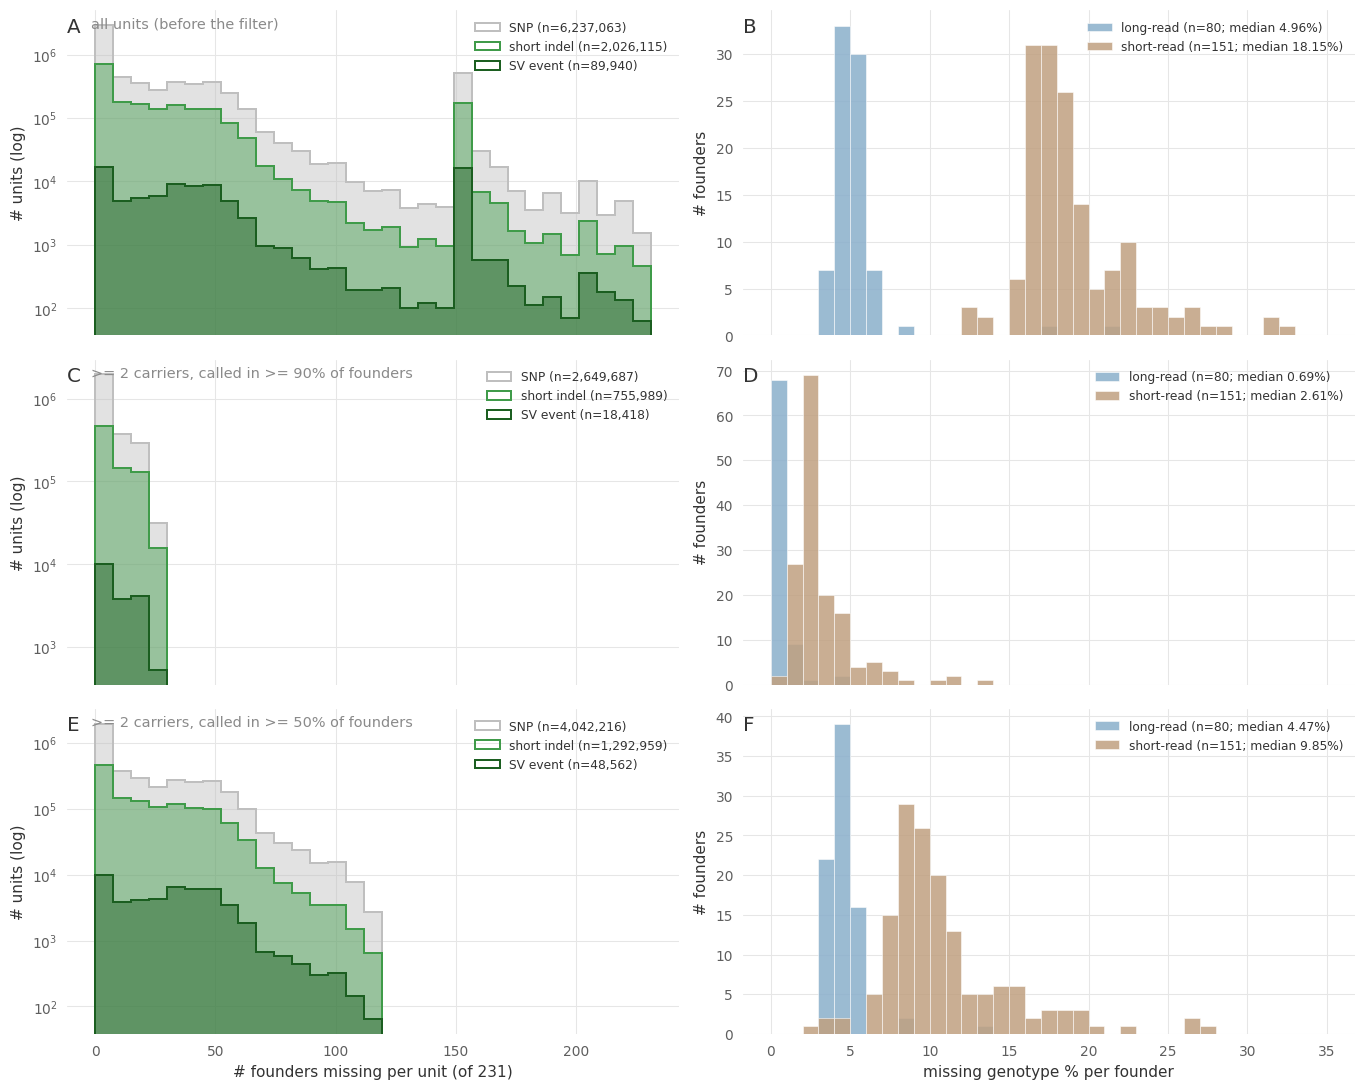

{'all': {'SNP': 6237063, 'indel': 2026115, 'SV events': 89940}, 'cr90': {'SNP': 2649687, 'indel': 755989, 'SV events': 18418}, 'cr50': {'SNP': 4042216, 'indel': 1292959, 'SV events': 48562}}


In [7]:
# 5b. The same two views AFTER the filter (events for SVs). Data: qc/_compute_panel_missing_events.py.
# Rows: no filter | >= 2 carriers & called in >= 90% of founders (the project filter) | same with >= 50%.
import sys
G = "/global/scratch/projects/fc_moilab/tbellg/kmate/analysis/grenenet_selection"
sys.path.insert(0, f"{G}/genes/convergence")
import plot_theme as TH
Zf = np.load(f"{G}/qc/results/panel_missing_events.npz", allow_pickle=True)
is_lr_f = Zf["is_longread"].astype(bool)
FSETS = [("all", "all units (before the filter)"), ("cr90", ">= 2 carriers, called in >= 90% of founders"),
         ("cr50", ">= 2 carriers, called in >= 50% of founders")]
FCLS = [("SNP", "SNP", TH.FAINT), ("indel", "short indel", TH.GREENS[1]), ("SV", "SV event", TH.GREENS[2])]
FCOH = {"long-read": "#8AAFCB", "short-read": "#C0A080"}
with plt.rc_context():                      # theme only for this figure; the rest of the notebook keeps its style
    TH.apply(); plt.rcParams["figure.dpi"] = 110
    fig, axes = plt.subplots(3, 2, figsize=(12.5, 10), sharex="col")
    xb = np.linspace(0, NF, 32); fb = np.arange(0, 36, 1.0)
    for r, (sname, lab) in enumerate(FSETS):
        ax = axes[r, 0]
        for c_, name, col in FCLS:
            v = Zf[f"miss_{sname}_{c_}"]
            ax.hist(v, bins=xb, histtype="stepfilled", color=col, alpha=0.45, linewidth=0)
            ax.hist(v, bins=xb, histtype="step", color=col, linewidth=1.3, label=f"{name} (n={len(v):,})")
        ax.set_yscale("log"); ax.set_ylabel("# units (log)"); ax.legend(loc="upper right")
        TH.panel(ax, "ABCDEF"[2*r], lab)
        ax = axes[r, 1]
        fc = Zf[f"fcalled_{sname}"]; tot = int(Zf[f"nunits_{sname}"].sum()); miss_pct = 100 * (1 - fc / tot)
        for coh, col in FCOH.items():
            sel = is_lr_f if coh == "long-read" else ~is_lr_f
            ax.hist(miss_pct[sel], bins=fb, color=col, alpha=0.85, edgecolor="white", linewidth=0.4,
                    label=f"{coh} (n={int(sel.sum())}; median {np.median(miss_pct[sel]):.2f}%)")
        ax.set_ylabel("# founders"); ax.legend(loc="upper right")
        TH.panel(ax, "ABCDEF"[2*r+1])
    axes[2, 0].set_xlabel(f"# founders missing per unit (of {NF})"); axes[2, 1].set_xlabel("missing genotype % per founder")
    fig.tight_layout(); fig.savefig(f"{PLOTDIR}/05b_missingness_events_before_after.png", dpi=170)
    plt.show()
print({sname: dict(zip(("SNP", "indel", "SV events"), Zf[f"nunits_{sname}"].tolist())) for sname, _ in FSETS})

## 6. Per-founder carrier counts (long-read vs short-read)

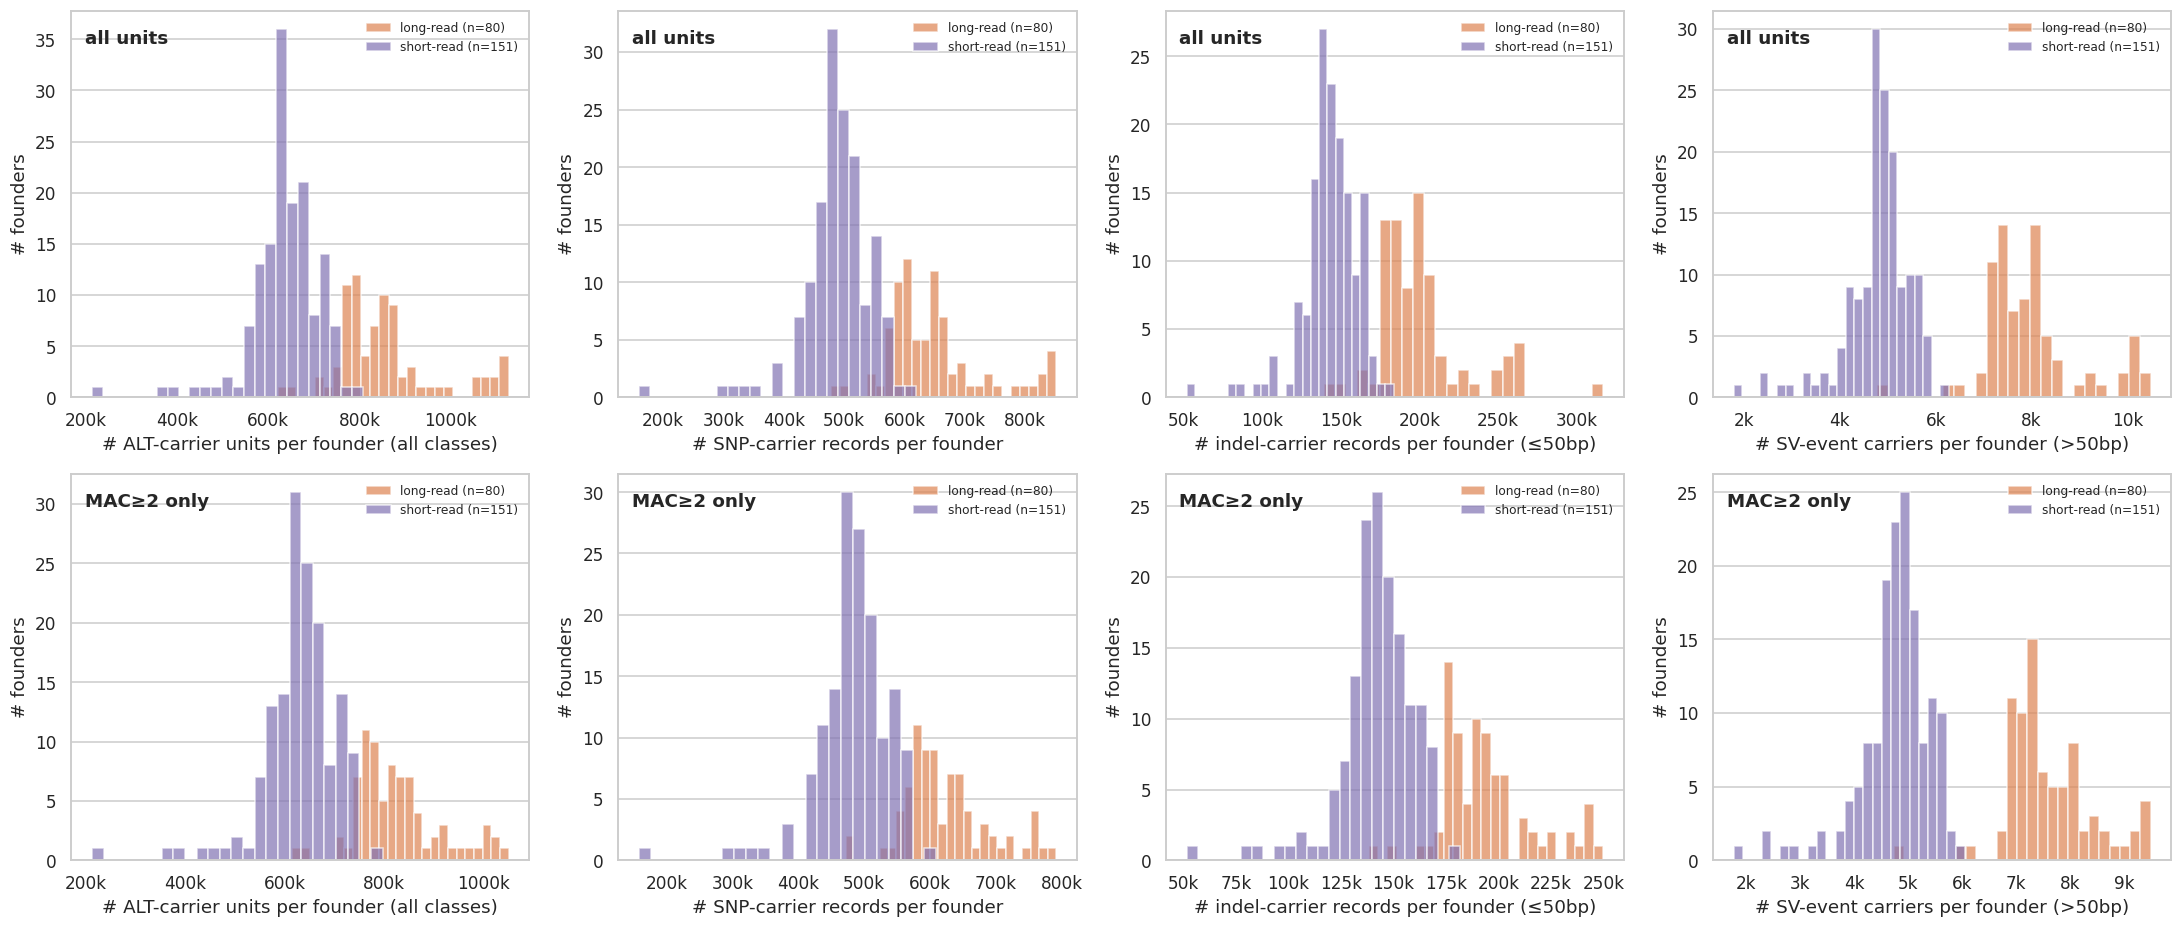

long-read (n=80): SNP 630,606 (MAC≥2: 610,349)  | indel 197,240 (MAC≥2: 190,330)  | SV 7,828 (MAC≥2: 7,395)  | all 837,283 (MAC≥2: 807,956)
short-read (n=151): SNP 491,653 (MAC≥2: 485,446)  | indel 144,079 (MAC≥2: 143,077)  | SV 4,883 (MAC≥2: 4,832)  | all 640,144 (MAC≥2: 633,118)


In [8]:
# 6. Per-founder carrier counts, long-read vs short-read cohort, one column per
# class (all classes, SNP, indel, SV). Top row: all records. Bottom row: MAC>=2
# only (singletons dropped) -- checks whether the long-read/short-read split is
# a singleton artifact or holds up.
def _kfmt(x, pos):
    return f"{x/1000:.0f}k" if abs(x) >= 1000 else f"{x:.0f}"

fig, axes = plt.subplots(2, 4, figsize=(20, 8.6))
panels = [("n_alt", "n_alt_mac2", "# ALT-carrier units per founder (all classes)"),
          ("n_snp_alt", "n_snp_alt_mac2", "# SNP-carrier records per founder"),
          ("n_indel_alt", "n_indel_alt_mac2", "# indel-carrier records per founder (≤50bp)"),
          ("n_sv_alt", "n_sv_alt_mac2", "# SV-event carriers per founder (>50bp)")]
for col_i, (col_all, col_mac2, xlabel) in enumerate(panels):
    for row_i, (col, tag) in enumerate([(col_all, "all units"), (col_mac2, "MAC≥2 only")]):
        ax = axes[row_i, col_i]
        for coh, color in [("long-read", COL_LONGREAD), ("short-read", COL_SHORTREAD)]:
            sub = founder[founder.cohort == coh]
            ax.hist(sub[col], bins=25, alpha=0.7, color=color, label=f"{coh} (n={len(sub)})")
        ax.set_xlabel(xlabel); ax.set_ylabel("# founders")
        ax.xaxis.set_major_formatter(plt.FuncFormatter(_kfmt))
        ax.annotate(tag, xy=(0.03, 0.95), xycoords="axes fraction", ha="left", va="top", fontweight="bold")
        ax.legend(frameon=False, fontsize=8)
        ax.grid(axis="x", visible=False)
plt.tight_layout()
fig.savefig(f"{PLOTDIR}/06_founder_carrier_counts.png", dpi=150, bbox_inches="tight")
plt.show()

for coh in ["long-read", "short-read"]:
    sub = founder[founder.cohort == coh]
    print(f"{coh} (n={len(sub)}): "
          f"SNP {int(sub.n_snp_alt.median()):,} (MAC≥2: {int(sub.n_snp_alt_mac2.median()):,})  "
          f"| indel {int(sub.n_indel_alt.median()):,} (MAC≥2: {int(sub.n_indel_alt_mac2.median()):,})  "
          f"| SV {int(sub.n_sv_alt.median()):,} (MAC≥2: {int(sub.n_sv_alt_mac2.median()):,})  "
          f"| all {int(sub.n_alt.median()):,} (MAC≥2: {int(sub.n_alt_mac2.median()):,})")

## 7. Genomic density along chromosomes

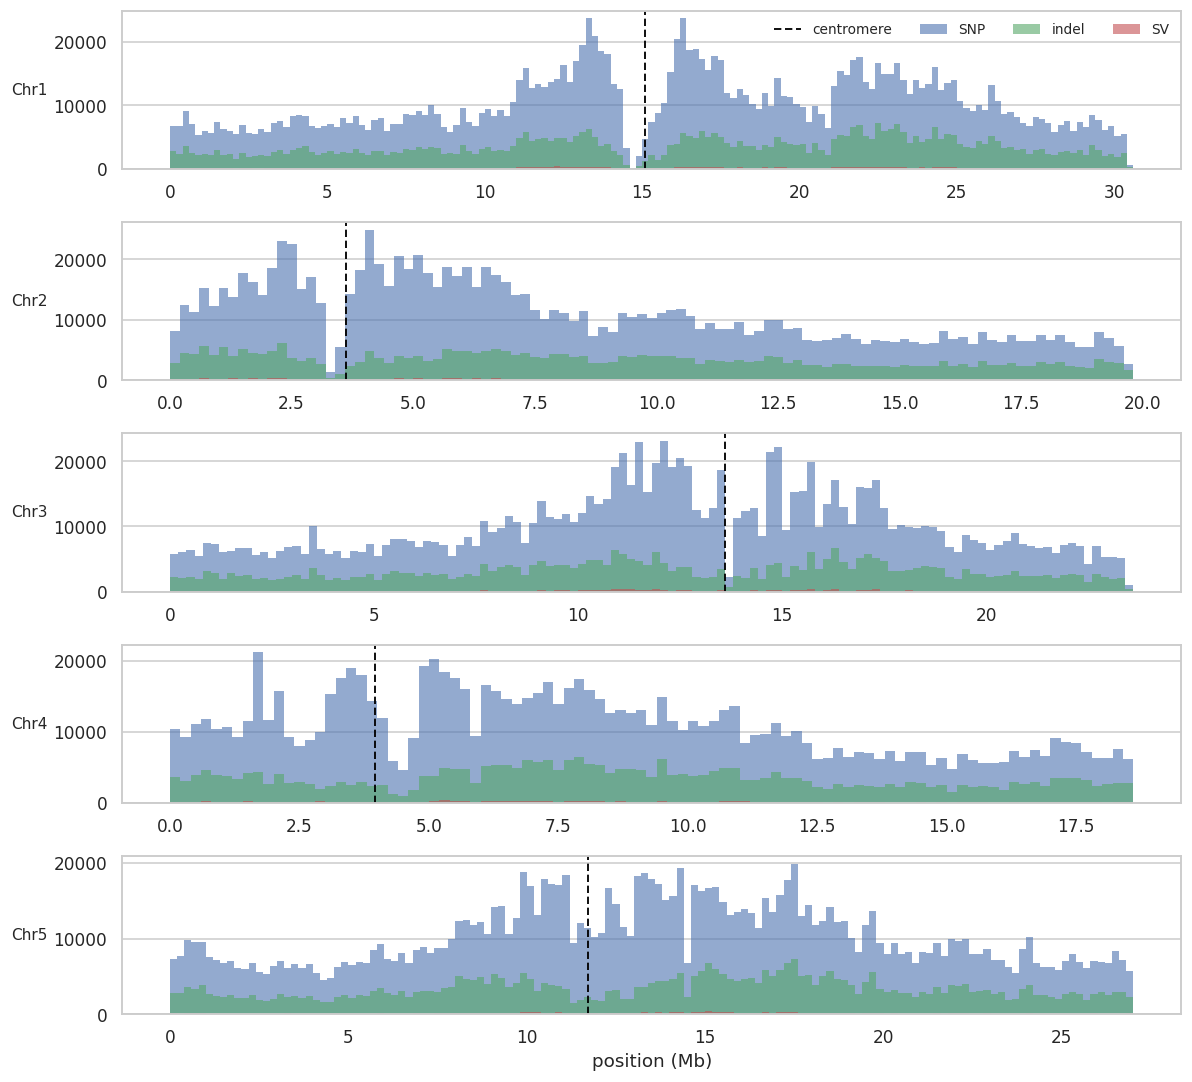

In [9]:
# 7. Genomic density -- variant density along each chromosome, by class.
# Overlaid (not stacked) with alpha: SVs are far rarer than SNP/indel, so stacking
# them on top buried their shape -- draw SNP/indel first, SV last (in front).
# Centromere midpoints (TAIR10), same values used elsewhere in this repo
# (analysis/grenenet_selection/extras/_sv_hap_context.py CEN).
CENTROMERE_MB = {"Chr1": 15.086, "Chr2": 3.607, "Chr3": 13.588, "Chr4": 3.956, "Chr5": 11.726}

BIN_BP = 200_000
fig, axes = plt.subplots(len(CHROMS), 1, figsize=(11, 2.0*len(CHROMS)), sharex=False)
for ax, c in zip(axes, CHROMS):
    Cl = f"Chr{c}"
    sub = rec[rec.chrom == Cl]
    max_pos = sub.pos.max()
    bins = np.arange(0, max_pos + BIN_BP, BIN_BP)
    for cls in CLASS_ORDER:   # SNP, indel, SV -- SV plotted last so it renders on top
        h, _ = np.histogram(sub.loc[sub.cls == cls, "pos"], bins=bins)
        ax.bar(bins[:-1] / 1e6, h, width=BIN_BP/1e6, color=CLASS_COLOR[cls], alpha=0.6,
               label=cls if c == CHROMS[0] else None, align="edge", linewidth=0)
    ax.axvline(CENTROMERE_MB[Cl], color="black", lw=1.2, ls=(0, (4, 2)),
               label="centromere" if c == CHROMS[0] else None)
    ax.set_ylabel(Cl, rotation=0, ha="right", va="center", fontsize=10)
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("position (Mb)")
axes[0].legend(frameon=False, loc="upper right", ncol=4, fontsize=9)
plt.tight_layout()
fig.savefig(f"{PLOTDIR}/07_genomic_density.png", dpi=150, bbox_inches="tight")
plt.show()

## Takeaways

Computed from the data above (events for SVs); see the table below.


In [10]:
# Key numbers, computed (no hard-coded text, so they cannot go stale)
cnt = rec.cls.value_counts().reindex(CLASS_ORDER)
sv_ev = rec[rec.cls == "SV"]
print("units:", {c: int(cnt[c]) for c in CLASS_ORDER}, "| total", f"{N_total:,}", f"| SV records collapsed: {N_sv_records:,}")
print(f"SV events: {100*(sv_ev.kind=='INS').mean():.1f}% insertions; largest {int(sv_ev.sv_size.max()):,} bp; median {int(sv_ev.sv_size.median()):,} bp")
mac = np.minimum(rec.ac, rec.an - rec.ac)
print("singletons (MAC=1):", {c: f"{100*(mac[rec.cls==c]==1).mean():.1f}%" for c in CLASS_ORDER})
print("median ALT frequency:", {c: round(float(np.nanmedian(rec.loc[rec.cls==c,'maf'])), 4) for c in CLASS_ORDER})
spike = rec[(rec.n_miss_founders >= 140) & (rec.n_miss_founders <= 160)]
print(f"missing-founder spike (140-160): {len(spike):,} units; SV share {100*(spike.cls=='SV').mean():.1f}%")
for coh in ["long-read", "short-read"]:
    sub = founder[founder.cohort == coh]
    print(f"{coh}: median % missing {100*np.median(sub.n_missing / N_total):.2f}; SV-event carriers per founder median "
          f"{int(sub.n_sv_alt.median()):,} (MAC>=2: {int(sub.n_sv_alt_mac2.median()):,})")

units: {'SNP': 6237063, 'indel': 2026115, 'SV': 89940} | total 8,353,118 | SV records collapsed: 226,468
SV events: 55.8% insertions; largest 291,065 bp; median 380 bp


singletons (MAC=1): {'SNP': '29.5%', 'indel': '30.6%', 'SV': '33.8%'}


median ALT frequency: {'SNP': 0.0211, 'indel': 0.0216, 'SV': 0.0187}


missing-founder spike (140-160): 725,071 units; SV share 2.4%
long-read: median % missing 4.96; SV-event carriers per founder median 7,828 (MAC>=2: 7,395)
short-read: median % missing 18.15; SV-event carriers per founder median 4,883 (MAC>=2: 4,832)
